# NewsBot 2.0 · Notebook 02 – Advanced Classification, Sentiment & Entities
**ITAI 2373 Final Project · Mourinho Hernanto**

**Goal:** build the Module A content-analysis engine: ensemble classifier with confidence and explanations, sentence-level sentiment with emotions, NER with relation extraction and a knowledge graph.

**Course modules:** 4–8 (POS/syntax, sentiment, classification, NER)

> Runs top-to-bottom in Google Colab (first cell installs everything). All logic lives in `src/` –
> this notebook demonstrates and evaluates it.

In [1]:
# ⚙️ Setup – works in Google Colab (clones the repo + installs) and locally
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content/ITAI2373-NewsBot-Final/ITAI2373-NewsBot-Final") if IN_COLAB else Path.cwd().resolve().parent
if IN_COLAB and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Haryapandhita/ITAI2373-NewsBot-Final.git",
                    "/content/ITAI2373-NewsBot-Final"], check=True)
sys.path.insert(0, str(ROOT))
from scripts.colab_setup import setup
ROOT = setup()

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
# Transformer models (summarisation, translation, multilingual embeddings) are used when
# available (Colab: Runtime -> Change runtime type -> T4 GPU recommended); otherwise
# NewsBot falls back to classical methods automatically.
USE_TRANSFORMERS = os.environ.get("NEWSBOT_USE_TRANSFORMERS", "1") == "1"
print("Transformers enabled:", USE_TRANSFORMERS)

Project root: /home/claude/NewsBot-Final/ITAI2373-NewsBot-Final  |  Colab: False


Transformers enabled: True


In [2]:
from src.data_processing.data_loader import load_all
from sklearn.model_selection import train_test_split
data = load_all(); bbc, webz = data["bbc"], data["webz"]
b = bbc.assign(full=bbc.title + ". " + bbc.text)
b_tr, b_te = train_test_split(b, test_size=0.2, stratify=b.category, random_state=42)
print(len(b_tr), "train /", len(b_te), "test")

1673 train / 419 test


## 1. Baselines vs. the NewsBot 2.0 ensemble (same split, no leakage)

In [3]:
from src.analysis.classifier import NewsClassifier, compare_baselines
base = compare_baselines(b_tr.full, b_tr.category, b_te.full, b_te.category)
clf = NewsClassifier().train(b_tr.full, b_tr.category)
ev = clf.evaluate(b_te.full, b_te.category)
base.loc[len(base)] = ["NewsBot 2.0 Ensemble (SVM+LR+NB, word+char)", ev["accuracy"], ev["macro_f1"], clf.train_seconds]
base.loc[len(base)] = ["Midterm Linear SVM (reported)", 0.9617, 0.9582, None]
base.sort_values("macro_f1", ascending=False)

20:29:39 | INFO    | src.analysis.classifier | Classifier trained on 1673 articles in 7.7s


,model,accuracy,macro_f1,train_s
2,Linear SVM (word TF-IDF) – midterm style,0.9785,0.9775,0.6349
3,Linear SVM (word+char TF-IDF),0.9761,0.9754,3.9661
1,Logistic Regression (word TF-IDF),0.9761,0.9751,0.3217
4,"NewsBot 2.0 Ensemble (SVM+LR+NB, word+char)",0.9737,0.9727,7.73314
0,Naive Bayes (word TF-IDF),0.9714,0.9699,0.1721
5,Midterm Linear SVM (reported),0.9617,0.9582,None


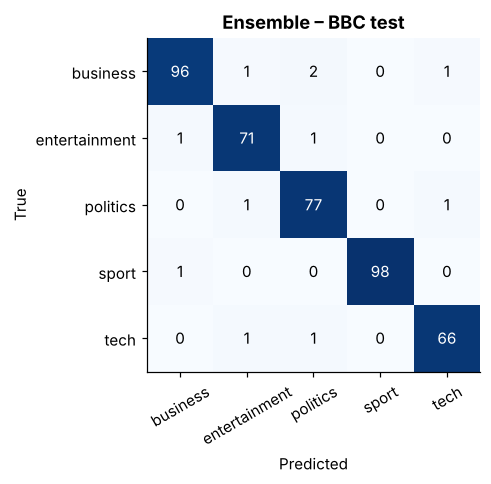

,class,precision,recall,f1-score,support
0,business,0.9796,0.9600,0.9697,100.0
1,entertainment,0.9595,0.9726,0.9660,73.0
2,politics,0.9506,0.9747,0.9625,79.0
3,sport,1.0000,0.9899,0.9949,99.0
4,tech,0.9706,0.9706,0.9706,68.0


In [4]:
from src.utils import visualization as viz
from src.utils.evaluation import per_class_table
viz.confusion_matrix_plot(ev["confusion_matrix"], ev["labels"], "Ensemble – BBC test"); plt.show()
per_class_table(ev["report"])

In [5]:
print("5-fold CV macro-F1 on the training split:", clf.cross_validate(b_tr.full, b_tr.category, folds=5))

5-fold CV macro-F1 on the training split: {'folds': 5, 'mean': 0.9796, 'std': 0.0043}


## 2. Confidence you can trust
Calibrated probabilities: when the model says 90%, it should be right ~90% of the time. Articles with low confidence or a small
margin between the top two classes are flagged `needs_review` for a human editor.

In [6]:
clf.calibration_table(b_te.full, b_te.category)

,bin,n,mean_confidence,accuracy
0,0.2-0.4,2,0.368,0.500
1,0.4-0.6,7,0.535,0.571
2,0.6-0.8,15,0.699,0.800
3,0.8-1.0,395,0.972,0.990


In [7]:
p = clf.predict_with_confidence("Manchester United's shares jumped after the club announced record TV revenue.")
p.to_dict()

{'label': 'business',
 'confidence': 0.453,
 'margin': 0.0003,
 'probabilities': {'business': 0.453,
  'sport': 0.4528,
  'entertainment': 0.0731,
  'politics': 0.0109,
  'tech': 0.0102},
 'secondary_labels': ['sport'],
 'needs_review': True}

## 3. Explaining a decision

In [8]:
exp = clf.explain_prediction("The new smartphone chip doubles battery life, analysts expect strong sales.")
print(exp["prediction"]["label"], exp["prediction"]["confidence"])
print("Key terms:", exp["key_terms"])
pd.DataFrame(exp["similar_training_articles"])

business 0.4179
Key terms: [('analysts', 0.3107), ('sales', 0.2732), ('strong', 0.1136), ('strong sales', 0.0839), ('expect', 0.0288), ('analysts expect', 0.0258), ('new', 0.0226)]


,label,similarity,snippet
0,tech,0.102,"Mobiles 'not media players yet'. Mobiles are not yet ready to be all-singing, all-dancing multimedia devices which w..."
1,business,0.092,Renault boss hails 'great year'. Strong sales outside western Europe helped Renault boost its profits by more than 4...
2,tech,0.092,Cheaper chip for mobiles. A mobile phone chip which combines a modem and a computer processor on one bit of silicon ...


## 4. Domain shift: does a 2004 model understand 2026 news?
We test the BBC-trained model on **English Webz articles from 2023–2026** (4 shared categories). Vocabulary such as
"AI", "crypto" or "TikTok" did not exist in 2004 – accuracy drops sharply. NewsBot 2.0 therefore trains on BBC **plus**
a balanced sample of recent Webz articles (test articles excluded).

In [9]:
from src.newsbot import training_frame
w = webz[webz.language == "en"].assign(full=lambda d: d.title + ". " + d.text)
_, w_te = train_test_split(w, test_size=0.3, stratify=w.category, random_state=42)
old = clf.evaluate(w_te.full, w_te.category)
train2 = training_frame(bbc, webz)
clf2 = NewsClassifier().train(train2.full, train2.category)
new = clf2.evaluate(w_te.full, w_te.category)
bbc_new = clf2.evaluate(b_te.full, b_te.category)
pd.DataFrame({"BBC-only model": [old["accuracy"], old["macro_f1"], ev["accuracy"]],
              "NewsBot 2.0 model": [new["accuracy"], new["macro_f1"], bbc_new["accuracy"]]},
             index=["Webz 2023-26 accuracy", "Webz 2023-26 macro-F1", "BBC test accuracy"])

20:30:43 | INFO    | src.analysis.classifier | Classifier trained on 4073 articles in 30.9s


,BBC-only model,NewsBot 2.0 model
Webz 2023-26 accuracy,0.6875,0.8296
Webz 2023-26 macro-F1,0.5595,0.6534
BBC test accuracy,0.9737,0.9642


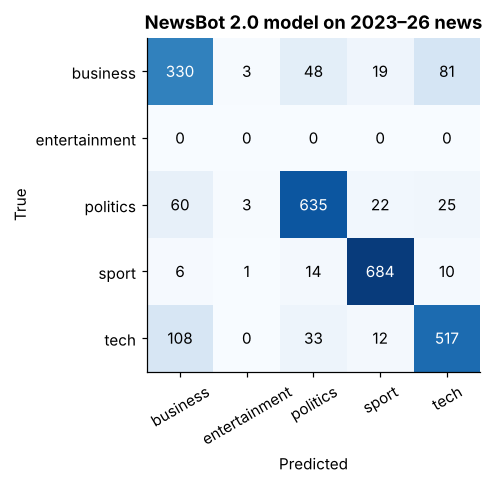

In [10]:
fig = viz.confusion_matrix_plot(new["confusion_matrix"], new["labels"], "NewsBot 2.0 model on 2023–26 news"); plt.show()

## 5. Multi-label output
A story can belong to two sections. Secondary labels are returned when their probability ≥ 0.20.

In [11]:
for t in ["Chelsea football club reported a £90m loss as wages and transfer fees rose, the club's accounts show.",
          "The government will regulate artificial intelligence companies under a new law passed by parliament."]:
    p = clf2.predict_with_confidence(t); print(p.label, p.confidence, "secondary:", p.secondary_labels, "| review:", p.needs_review)

sport 0.8392 secondary: [] | review: False
politics 0.5243 secondary: ['tech'] | review: True


## 6. Optional – multilingual zero-shot classification with sentence embeddings
With the multilingual MiniLM encoder, a classifier trained on **English** articles can label **Spanish/German/French**
articles directly (shared embedding space). Runs when `sentence-transformers` is available (Colab).

In [12]:
from src.language_models.embeddings import SemanticEmbedder
from src.analysis.classifier import EmbeddingClassifier
emb = SemanticEmbedder(use_transformer=USE_TRANSFORMERS)
if emb.backend == "sentence-transformers":
    ec = EmbeddingClassifier(emb).train(train2.full.tolist(), train2.category.tolist())
    rows = []
    for lang in ["es", "de", "fr", "it", "pt"]:
        s = webz[webz.language == lang].sample(200, random_state=0)
        tfidf_acc = clf2.evaluate((s.title + ". " + s.text).tolist(), s.category.tolist())["accuracy"]
        emb_acc = float(np.mean(np.array(ec.predict((s.title + ". " + s.text).tolist())) == s.category.values))
        rows.append({"language": lang, "TF-IDF model": tfidf_acc, "multilingual embeddings": round(emb_acc, 4)})
    display(pd.DataFrame(rows))
else:
    print("Sentence-transformers not available here – run in Colab to see zero-shot multilingual classification.")

20:30:50 | WARNING | src.language_models.embeddings | Sentence-Transformer unavailable (No module named 'sentence_transformers') – falling back to LSA


Sentence-transformers not available here – run in Colab to see zero-shot multilingual classification.


## 7. Sentiment: sentence-level VADER + news lexicon + emotions
The midterm found whole-article VADER saturates near ±1. NewsBot averages per sentence and corrects news words
("party", "penalty", "shares" are neutral). We evaluate against Webz's sentiment labels (English, positive vs. negative).

In [13]:
from src.analysis.sentiment_analyzer import SentimentAnalyzer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sa, plain = SentimentAnalyzer(), SentimentIntensityAnalyzer()
ev_s = webz[(webz.language == "en") & webz.webz_sentiment.isin(["positive", "negative"])].sample(1500, random_state=0)
texts = (ev_s.title + ". " + ev_s.text).tolist()
whole = np.array([plain.polarity_scores(t[:5000])["compound"] for t in texts])
sent_avg = np.array([np.mean(sa.sentence_scores(t) or [0]) for t in texts])
acc = lambda s: float((np.where(s >= 0, "positive", "negative") == ev_s.webz_sentiment.values).mean())
print(f"whole-text VADER accuracy      : {acc(whole):.3f}  (saturated |score|>0.9: {np.mean(np.abs(whole) > 0.9):.0%})")
print(f"sentence-average + news lexicon: {acc(sent_avg):.3f}")

whole-text VADER accuracy      : 0.690  (saturated |score|>0.9: 73%)
sentence-average + news lexicon: 0.706


In [14]:
sa.analyze("The striker scored a stunning winner. Fans celebrated, but the coach was angry about the referee.")

{'label': 'positive',
 'score': 0.137,
 'whole_text_vader': 0.0258,
 'confidence': 0.75,
 'positive_sentence_share': 0.5,
 'negative_sentence_share': 0.5,
 'most_positive_sentence': 'The striker scored a stunning winner.',
 'most_negative_sentence': 'Fans celebrated, but the coach was angry about the referee.',
 'emotions': {'anger': 0.1111,
  'anticipation': 0.2222,
  'disgust': 0.1111,
  'fear': 0.0,
  'joy': 0.2222,
  'sadness': 0.0,
  'surprise': 0.1111,
  'trust': 0.2222},
 'method': 'vader-sentence-average'}

## 8. Named entities, relations and the knowledge graph

In [15]:
from src.analysis.ner_extractor import EntityRelationshipMapper
mapper = EntityRelationshipMapper()
text = "Microsoft boss Bill Gates met Tony Blair in London. Tim Cook, chief executive of Apple, visited Berlin on Monday."
display(pd.DataFrame(mapper.extract_entities(text))[["text", "canonical", "label"]])
pd.DataFrame(mapper.extract_relationships(text))[["source", "relation", "target"]]

,text,canonical,label
0,Microsoft,Microsoft,ORG
1,Bill Gates,Bill Gates,PERSON
2,Tony Blair,Tony Blair,PERSON
3,London,London,GPE
4,Tim Cook,Tim Cook,PERSON
5,Apple,Apple,ORG
6,Berlin,Berlin,GPE
7,Monday,Monday,DATE


,source,relation,target
0,Bill Gates,ROLE_AT,Microsoft
1,Bill Gates,MEET,Tony Blair
2,Tim Cook,ROLE_AT,Apple
3,Tim Cook,VISIT,Berlin


**Midterm limitation fixed – casing matters for NER** (150 BBC test articles, PERSON/ORG/GPE entities):

In [16]:
s = b_te.sample(150, random_state=0)["text"]
count = lambda texts: sum(len([e for e in mapper.extract_entities(t) if e["label"] in ("PERSON", "ORG", "GPE")]) for t in texts)
cased, lower = count(s), count(s.str.lower())
print(f"original casing: {cased} entities | lower-cased (midterm data): {lower} entities | +{100*(cased-lower)/lower:.0f}%")

original casing: 3279 entities | lower-cased (midterm data): 1709 entities | +92%


20:32:02 | INFO    | src.analysis.ner_extractor | Knowledge graph: 5627 nodes, 28731 edges


,entity,type,mentions,degree
0,United States,GPE,602,1222
1,United Kingdom,GPE,581,1138
2,London,GPE,241,569
3,Europe,GPE,204,389
4,England,GPE,199,500
5,BBC,ORG,170,409
6,Labour,ORG,161,244
7,France,GPE,157,479
8,Tony Blair,PERSON,141,248
9,Wales,GPE,123,361


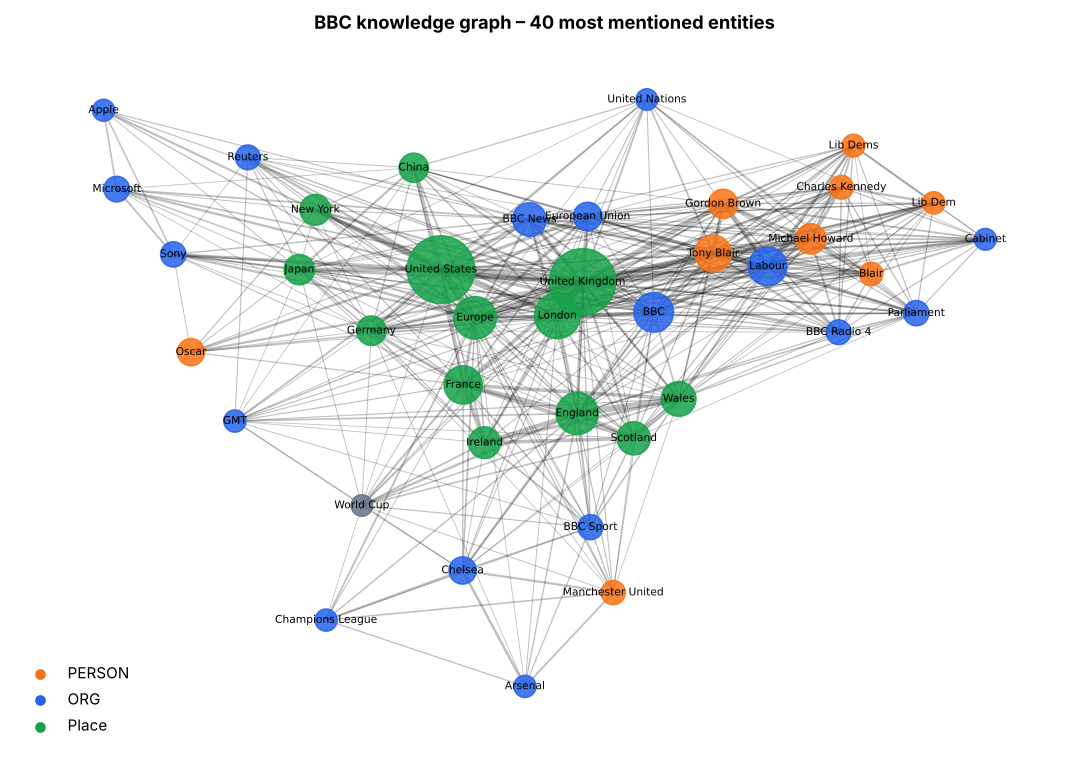

In [17]:
g = mapper.build_knowledge_graph(b.full.str[:3000], b.category)
display(mapper.top_entities(10))
viz.network(g, "BBC knowledge graph – 40 most mentioned entities"); plt.show()

In [18]:
for a, c in [("Blair", "Brown"), ("Microsoft", "Google"), ("Arsenal", "Chelsea")]:
    print(a, "↔", c, "→", mapper.find_entity_connections(a, c))
mapper.entity_profile("Tony Blair")

Blair ↔ Brown → {'found': True, 'direct': True, 'paths': [['Blair', 'Brown']], 'weight': 13, 'relations': {'HIT': 1, 'TELL': 3, 'GO': 3, 'REINSTATE': 1}}
Microsoft ↔ Google → {'found': True, 'direct': True, 'paths': [['Microsoft', 'Google']], 'weight': 12, 'relations': {'TRAIL': 1}}
Arsenal ↔ Chelsea → {'found': True, 'direct': True, 'paths': [['Arsenal', 'Chelsea']], 'weight': 23, 'relations': {'HOLD': 1, 'LEAD': 1}}


{'found': True,
 'name': 'Tony Blair',
 'type': 'PERSON',
 'mentions': 141,
 'categories': {'business': 4,
  'entertainment': 1,
  'politics': 134,
  'sport': 1,
  'tech': 1},
 'top_connections': [('Labour', 85, {'PROMPT': 1, 'ROLE_AT': 2, 'TELL': 1}),
  ('United Kingdom', 79, {'APOLOGISE': 1, 'HAVE': 1, 'DAMAGE': 1}),
  ('Michael Howard', 57, {'WRITE': 1, 'ACCUSE': 1}),
  ('Gordon Brown',
   45,
   {'BACK': 1,
    'CRITICISE': 1,
    'DISMISS': 1,
    'FACE': 1,
    'PROMISE': 1,
    'KNOW': 1}),
  ('Iraq', 30, {'SET': 1, 'REJECT': 1})]}

## Key takeaways
* On clean BBC data every strong model reaches 97–98% – differences of <1 point are within noise on 419 test articles.
  The jump over the midterm (96.2%) mostly comes from **better data** (original casing + headlines). We keep the ensemble
  because it gives **calibrated probabilities** (a plain SVM has none), which power the review flag and multi-label output.
* A 2004-only model loses a lot of accuracy on 2023–26 news; adding recent articles recovers it → real-world robustness.
* Sentence-averaged sentiment agrees with the external labels slightly more often than whole-article VADER (≈+1.5 points)
  and, more importantly, no longer saturates at ±1 – scores become comparable between articles.
* Original casing multiplies the number of recognised entities; relation patterns (ROLE_AT, verbs) turn co-mentions into a knowledge graph.